# Medir el error: MSE y entropía cruzada en la práctica

Entrenar es repetir tres pasos: **medir** cuánto se equivoca el modelo, **diagnosticar** cuánto contribuye cada parámetro a ese error y **actualizar** los parámetros. Este notebook trata el primero. El siguiente, `02_gradientes_y_optimizadores`, trata los otros dos.

En el módulo 1 las funciones de pérdida se dedujeron a partir de la máxima verosimilitud (`04-matematica-de-pytorch/03_funciones_de_perdida`). Aquí el foco es práctico: cuál usar en cada problema, qué esperan recibir y qué pasa cuando se elige mal.

**Contenido**

1. Preparación
2. Medir, diagnosticar, actualizar
3. Por qué el error se eleva al cuadrado
4. MSE castiga más los errores grandes
5. De puntajes a probabilidades
6. Entropía cruzada: el costo de equivocarse con confianza
7. Lo que espera `CrossEntropyLoss`
8. MSE para clasificar, entropía cruzada para regresión
9. Las pérdidas no se comparan entre sí
10. Resumen y ejercicios

## 1. Preparación

En la sección 8 entrenamos varias redes sobre MNIST. Para que cada una tarde segundos, precargamos las imágenes ya normalizadas en un tensor, como en `00-datos/01_transforms_dataset_y_dataloader` (sección 9).

In [1]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(0)


def precargar(entrenamiento):
    datos = datasets.MNIST(root="../data", train=entrenamiento, download=True)
    imagenes = ((datos.data.float() / 255 - 0.1307) / 0.3081).unsqueeze(1)
    return imagenes, datos.targets


X_entrenamiento, y_entrenamiento = precargar(True)
X_prueba, y_prueba = precargar(False)
print("entrenamiento:", tuple(X_entrenamiento.shape), "  prueba:", tuple(X_prueba.shape))

entrenamiento: (60000, 1, 28, 28)   prueba: (10000, 1, 28, 28)


## 2. Medir, diagnosticar, actualizar

| Paso | Código | Qué hace |
|---|---|---|
| Medir | `perdida = criterio(salida, y)` | Compara las predicciones con las respuestas y devuelve un número |
| Diagnosticar | `perdida.backward()` | Calcula cuánto influye cada parámetro en ese número |
| Actualizar | `optimizador.step()` | Mueve cada parámetro en la dirección que lo baja |

Toda función de pérdida hace lo mismo: compara la predicción con la respuesta real y devuelve **un solo número**, más alto mientras peor sea la predicción. Tiene que ser un solo número porque `backward()` deriva un escalar (`04-matematica-de-pytorch/01_autograd_y_regla_de_la_cadena`, sección 5). Lo que cambia de una pérdida a otra es qué cuenta como "peor".

## 3. Por qué el error se eleva al cuadrado

Volvamos a las entregas del módulo 1. Dos pedidos tardaron 30 minutos cada uno, y el modelo predijo 32 y 28. Se equivocó por 2 minutos en cada uno, en direcciones opuestas:

In [2]:
real = torch.tensor([30.0, 30.0])
prediccion = torch.tensor([32.0, 28.0])
error = prediccion - real

print("errores          :", error.tolist())
print("error promedio   :", error.mean().item())
print("MSE              :", nn.MSELoss()(prediccion, real).item())
print("MSE a mano       :", (error ** 2).mean().item())

errores          : [2.0, -2.0]
error promedio   : 0.0
MSE              : 4.0
MSE a mano       : 4.0


El promedio de los errores da 0, como si el modelo fuera perfecto, porque el +2 y el −2 se cancelan. Al elevar al cuadrado los dos errores quedan positivos y se suman. Eso es el **error cuadrático medio** (MSE):

$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (\hat{y}_i - y_i)^2$$

## 4. MSE castiga más los errores grandes

Elevar al cuadrado tiene un segundo efecto: un error de 10 cuesta 100, cien veces más que un error de 1. Comparamos dos modelos que se equivocan en el mismo total de minutos, repartido de forma distinta:

In [3]:
real = torch.full((10,), 30.0)
modelo_a = real + torch.tensor([1.0, -1, 1, -1, 1, -1, 1, -1, 1, -1])     # diez errores de 1 minuto
modelo_b = real + torch.tensor([0.0, 0, 0, 0, 0, 0, 0, 0, 0, 10])         # un solo error de 10 minutos

for nombre, pred in [("A: diez errores de 1 min", modelo_a), ("B: un error de 10 min", modelo_b)]:
    print(f"{nombre:26s} error absoluto medio {nn.L1Loss()(pred, real):.1f}   MSE {nn.MSELoss()(pred, real):.1f}")

A: diez errores de 1 min   error absoluto medio 1.0   MSE 1.0
B: un error de 10 min      error absoluto medio 1.0   MSE 10.0


Con el error absoluto medio (`L1Loss`) los dos modelos empatan. Con MSE el modelo B es diez veces peor. Para el repartidor, que puede perder el trabajo por una sola entrega muy tarde, el MSE describe mejor el problema. La otra cara es que un dato atípico pesa mucho en el MSE; para esos casos están `L1Loss` y `HuberLoss` (`04-matematica-de-pytorch/03_funciones_de_perdida`, secciones 3 y 4).

`nn.MSELoss()` es la elección por defecto cuando se predice **un número**: un tiempo, un precio, una temperatura, una distancia.

## 5. De puntajes a probabilidades

En clasificación el modelo no predice un número sino **una clase**. La red de MNIST entrega 10 números por imagen, uno por dígito. Esos números, llamados **logits**, pueden ser cualquier valor real. Para leerlos como probabilidades se pasan por `softmax`, que los vuelve positivos (con la exponencial) y los divide por su suma para que sumen 1:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

Con una red recién creada, sin entrenar:

In [4]:
torch.manual_seed(0)
red = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))

with torch.no_grad():
    logits = red(X_entrenamiento[:1])
probabilidades = logits.softmax(dim=1)

print("logits         :", [round(v, 2) for v in logits[0].tolist()])
print("probabilidades :", [round(v, 3) for v in probabilidades[0].tolist()])
print("suma           :", round(probabilidades.sum().item(), 4))
print("predicción:", logits.argmax(dim=1).item(), "  etiqueta real:", y_entrenamiento[0].item())

logits         : [0.16, 0.15, -0.28, -0.06, -0.41, -0.08, 0.0, 0.33, 0.06, 0.01]
probabilidades : [0.116, 0.115, 0.075, 0.094, 0.065, 0.092, 0.099, 0.138, 0.105, 0.101]
suma           : 1.0
predicción: 7   etiqueta real: 5


Sin entrenar, la red reparte la probabilidad casi por igual, alrededor de 10% para cada dígito. La predicción es el dígito con el logit más alto. Como `softmax` no cambia el orden de los valores, el más alto es el mismo antes y después: para predecir la clase no hace falta calcular las probabilidades.

## 6. Entropía cruzada: el costo de equivocarse con confianza

La entropía cruzada mira solo la probabilidad que el modelo le dio a la clase correcta, $p_{\text{correcta}}$, y cobra

$$\text{pérdida} = -\log p_{\text{correcta}}$$

Si el modelo le dio probabilidad 1 a la clase correcta, la pérdida es 0. Mientras menos le dé, más cobra, y sin límite. Cuatro situaciones con una imagen que es un **3**:

In [5]:
def distribucion(asignadas):
    """Probabilidades para los 10 dígitos: las indicadas y el resto repartido en partes iguales."""
    p = torch.full((10,), (1 - sum(asignadas.values())) / (10 - len(asignadas)))
    for digito, prob in asignadas.items():
        p[digito] = prob
    return p


casos = {
    "95% seguro de que es un 7": {7: 0.95, 3: 0.04},
    "55% seguro de que es un 7": {7: 0.55, 3: 0.40},
    "55% seguro de que es un 3": {3: 0.55, 7: 0.40},
    "95% seguro de que es un 3": {3: 0.95, 7: 0.04},
}
criterio = nn.CrossEntropyLoss()
etiqueta = torch.tensor([3])

for nombre, asignadas in casos.items():
    p = distribucion(asignadas)
    logits = p.log().unsqueeze(0)                  # softmax(log p) = p, así que log p sirve de logits
    print(f"{nombre:28s} p(3) = {p[3]:.2f}   pérdida = {criterio(logits, etiqueta).item():.2f}"
          f"   (a mano: {-p[3].log().item():.2f})")

95% seguro de que es un 7    p(3) = 0.04   pérdida = 3.22   (a mano: 3.22)
55% seguro de que es un 7    p(3) = 0.40   pérdida = 0.92   (a mano: 0.92)
55% seguro de que es un 3    p(3) = 0.55   pérdida = 0.60   (a mano: 0.60)
95% seguro de que es un 3    p(3) = 0.95   pérdida = 0.05   (a mano: 0.05)


Equivocarse con 95% de seguridad cuesta 3.22; equivocarse dudando, 0.92. Las dos respuestas son incorrectas (las dos dicen "7"), pero la confiada cuesta tres veces y media más. Al revés, acertar dudando todavía cuesta algo (0.60), así que el modelo sigue aprendiendo hasta que acierta con seguridad. La curva completa:

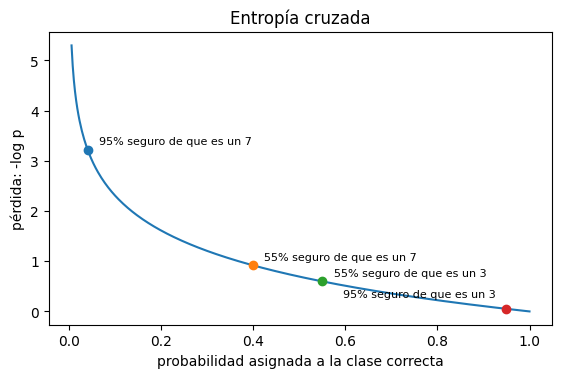

In [6]:
p = torch.linspace(0.005, 1, 400)

plt.figure(figsize=(6.5, 3.8))
plt.plot(p, -p.log())
for nombre, asignadas in casos.items():
    p3 = asignadas[3]
    plt.scatter(p3, -torch.tensor(p3).log(), zorder=3)
    plt.annotate(nombre, (p3, -torch.tensor(p3).log()), textcoords="offset points", fontsize=8,
                 xytext=(-8, 8) if p3 > 0.9 else (8, 4), ha="right" if p3 > 0.9 else "left")
plt.xlabel("probabilidad asignada a la clase correcta")
plt.ylabel("pérdida: -log p")
plt.title("Entropía cruzada")
plt.show()

`nn.CrossEntropyLoss()` es la elección por defecto cuando se predice **una categoría**: un dígito, una especie de animal, la palabra siguiente de un texto.

## 7. Lo que espera `CrossEntropyLoss`

`nn.CrossEntropyLoss()(salida, etiquetas)` espera:

- **`salida`**: los **logits**, con forma `[lote, clases]` y tipo `float`. No las probabilidades: la función aplica `softmax` por dentro, de una forma más estable numéricamente (`04-matematica-de-pytorch/02_capas_y_activaciones`, sección 10).
- **`etiquetas`**: el número de la clase correcta de cada ejemplo, con forma `[lote]` y tipo `int64`. Es lo que entrega el `DataLoader` de MNIST.

Los errores típicos son de forma o de tipo en las etiquetas:

In [7]:
salida = torch.randn(4, 10)
variantes = {
    "int64, forma [4] (lo correcto)": torch.tensor([1, 2, 3, 4]),
    "float, forma [4]": torch.tensor([1.0, 2.0, 3.0, 4.0]),
    "int64, forma [4, 1]": torch.tensor([[1], [2], [3], [4]]),
}
for nombre, etiquetas in variantes.items():
    try:
        print(f"{nombre:32s} pérdida = {criterio(salida, etiquetas).item():.4f}")
    except RuntimeError as error:
        print(f"{nombre:32s} RuntimeError: {error}")

int64, forma [4] (lo correcto)   pérdida = 3.1206
float, forma [4]                 RuntimeError: expected scalar type Long but found Float
int64, forma [4, 1]              RuntimeError: 0D or 1D target tensor expected, multi-target not supported


Se arreglan con `etiquetas.long()` y `etiquetas.squeeze(1)`. (La función también acepta etiquetas como probabilidades por clase, con forma `[lote, clases]` y tipo `float`, por ejemplo vectores one-hot. Con one-hot da lo mismo que con el número de clase.)

El error más traicionero no da ningún mensaje: **aplicar `softmax` dentro del modelo** y después pasarle el resultado a `CrossEntropyLoss`. La función aplica su propio `softmax` encima del anterior. Como las probabilidades están entre 0 y 1, el segundo `softmax` nunca puede concentrar la probabilidad en una clase, y la pérdida tiene un piso. Con una predicción perfecta:

In [8]:
perfecta = torch.tensor([[0.0, 0, 0, 20, 0, 0, 0, 0, 0, 0]])      # logits: todo apunta al 3
print("logits a CrossEntropyLoss            :", round(criterio(perfecta, etiqueta).item(), 4))
print("softmax antes de CrossEntropyLoss    :", round(criterio(perfecta.softmax(dim=1), etiqueta).item(), 4))

e = torch.tensor(1.0).exp()
print("piso con 10 clases, log((e + 9) / e) :", round(torch.log((e + 9) / e).item(), 4))

logits a CrossEntropyLoss            : 0.0
softmax antes de CrossEntropyLoss    : 1.4612
piso con 10 clases, log((e + 9) / e) : 1.4612


Con el doble `softmax`, la pérdida de una predicción perfecta es 1.46 en vez de 0, y los gradientes se achican. El modelo igual aprende algo, así que el error pasa inadvertido. En la sección siguiente se ve cuánto pierde.

## 8. MSE para clasificar, entropía cruzada para regresión

**MSE para clasificar.** Se puede: se convierten las etiquetas a vectores one-hot (un 1 en la clase correcta y 0 en el resto) y se mide el MSE contra las probabilidades del modelo. El problema está en el gradiente. Calculamos con autograd cuánto empuja cada pérdida al logit de la clase correcta, según la probabilidad que el modelo ya le da:

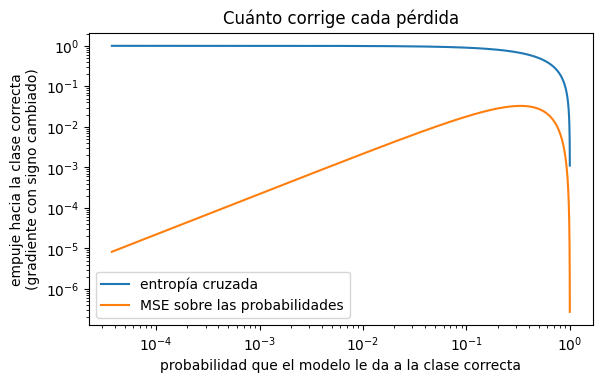

In [9]:
puntajes = torch.linspace(-8, 9, 300)
probabilidad, gradiente_ec, gradiente_mse = [], [], []

for s in puntajes:
    logits = torch.zeros(1, 10)
    logits[0, 3] = s                       # el 3 es la clase correcta; los demás logits valen 0
    logits.requires_grad_(True)

    perdida_ec = criterio(logits, etiqueta)
    perdida_mse = F.mse_loss(logits.softmax(dim=1), F.one_hot(etiqueta, 10).float())
    g_ec, = torch.autograd.grad(perdida_ec, logits)
    g_mse, = torch.autograd.grad(perdida_mse, logits)

    probabilidad.append(logits.softmax(dim=1)[0, 3].item())
    gradiente_ec.append(-g_ec[0, 3].item())
    gradiente_mse.append(-g_mse[0, 3].item())

plt.figure(figsize=(6.5, 3.8))
plt.plot(probabilidad, gradiente_ec, label="entropía cruzada")
plt.plot(probabilidad, gradiente_mse, label="MSE sobre las probabilidades")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("probabilidad que el modelo le da a la clase correcta")
plt.ylabel("empuje hacia la clase correcta\n(gradiente con signo cambiado)")
plt.title("Cuánto corrige cada pérdida")
plt.legend()
plt.show()

Los dos ejes son logarítmicos. Con entropía cruzada, el gradiente respecto del logit correcto es $p_{\text{correcta}} - 1$: mientras más equivocado está el modelo, más fuerte es la corrección, hasta un máximo de 1. Con MSE pasa lo contrario en la zona que más importa. Su empuje máximo, de apenas 0.03, llega cuando el modelo ya le da cerca de un 30% a la clase correcta, y desde ahí hacia la izquierda cae en línea recta: con probabilidad 0.001 es unas cien veces más débil que con 0.1. La pendiente del `softmax` es casi plana en esa zona, y la corrección se pierde. El error confiado, el peor de todos, es el que menos se corrige. (Además el gradiente del MSE es chico en todas partes, porque los errores son diferencias entre números de 0 a 1 y se promedian entre las 10 clases.)

Lo comprobamos entrenando la misma red tres veces durante una época: con entropía cruzada, con MSE sobre las probabilidades y con el doble `softmax` de la sección anterior. Medimos la exactitud de prueba cada 50 lotes. Lo hacemos con `SGD` y con `Adam`, los dos optimizadores del siguiente notebook:

In [10]:
def mse_sobre_probabilidades(salida, etiquetas):
    return F.mse_loss(salida.softmax(dim=1), F.one_hot(etiquetas, 10).float())


def doble_softmax(salida, etiquetas):
    return F.cross_entropy(salida.softmax(dim=1), etiquetas)


def exactitud(modelo):
    with torch.no_grad():
        return (modelo(X_prueba).argmax(dim=1) == y_prueba).float().mean().item()


def entrenar_una_epoca(perdida, crear_optimizador, cada=50):
    torch.manual_seed(0)
    modelo = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    optimizador = crear_optimizador(modelo.parameters())
    cargador = DataLoader(TensorDataset(X_entrenamiento, y_entrenamiento), batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(1))
    pasos, exactitudes, perdidas = [0], [exactitud(modelo)], []
    for i, (x, y) in enumerate(cargador, start=1):
        optimizador.zero_grad()
        valor = perdida(modelo(x), y)
        valor.backward()
        optimizador.step()
        perdidas.append(valor.item())
        if i % cada == 0 or i == len(cargador):
            pasos.append(i)
            exactitudes.append(exactitud(modelo))
    return pasos, exactitudes, perdidas


perdidas_a_probar = {
    "entropía cruzada": F.cross_entropy,
    "MSE sobre probabilidades": mse_sobre_probabilidades,
    "softmax + entropía cruzada": doble_softmax,
}
optimizadores = {
    "SGD, lr = 0.1": lambda parametros: torch.optim.SGD(parametros, lr=0.1),
    "Adam, lr = 0.001": lambda parametros: torch.optim.Adam(parametros, lr=0.001),
}

resultados = {}
for nombre_opt, crear in optimizadores.items():
    for nombre_perdida, perdida in perdidas_a_probar.items():
        pasos, exactitudes, _ = resultados[nombre_opt, nombre_perdida] = entrenar_una_epoca(perdida, crear)
        print(f"{nombre_opt:17s} {nombre_perdida:28s} exactitud a los 100 lotes {exactitudes[pasos.index(100)]:.1%}"
              f"   al final {exactitudes[-1]:.1%}")

SGD, lr = 0.1     entropía cruzada             exactitud a los 100 lotes 88.5%   al final 94.1%


SGD, lr = 0.1     MSE sobre probabilidades     exactitud a los 100 lotes 46.4%   al final 89.0%


SGD, lr = 0.1     softmax + entropía cruzada   exactitud a los 100 lotes 79.6%   al final 92.1%


Adam, lr = 0.001  entropía cruzada             exactitud a los 100 lotes 90.4%   al final 95.6%


Adam, lr = 0.001  MSE sobre probabilidades     exactitud a los 100 lotes 90.6%   al final 95.3%


Adam, lr = 0.001  softmax + entropía cruzada   exactitud a los 100 lotes 88.8%   al final 94.2%


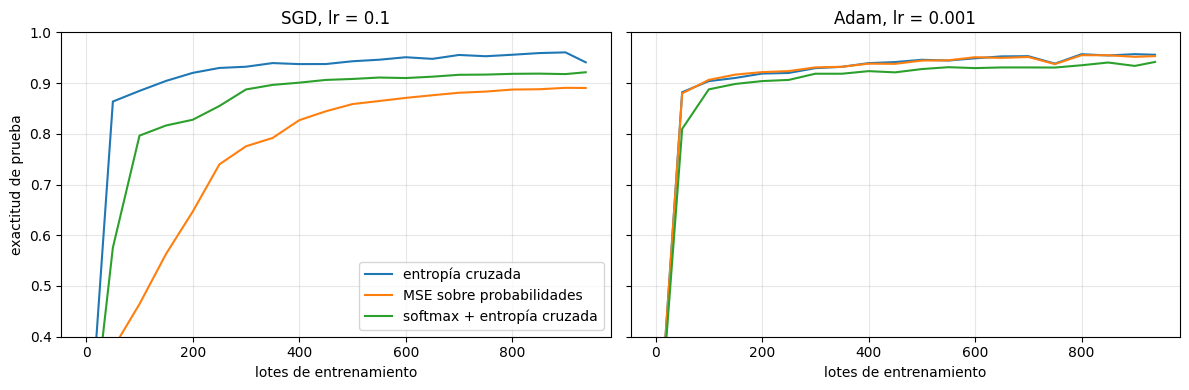

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eje, nombre_opt in zip(ejes, optimizadores):
    for nombre_perdida in perdidas_a_probar:
        pasos, exactitudes, _ = resultados[nombre_opt, nombre_perdida]
        eje.plot(pasos, exactitudes, label=nombre_perdida)
    eje.set_title(nombre_opt)
    eje.set_xlabel("lotes de entrenamiento")
    eje.set_ylim(0.4, 1)
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("exactitud de prueba")
ejes[0].legend()
plt.tight_layout()
plt.show()

Con `SGD`, la diferencia es clara. A los 100 lotes la entropía cruzada ya acierta el 88% y el MSE el 46%; al final de la época, 94% contra 89%. El doble `softmax` queda en medio, en 92%: aprende, pero siempre por debajo. (La bajada de la entropía cruzada en el último tramo, de 96% a 94%, es el ruido propio de `SGD` con una tasa grande: la exactitud sube y baja de un lote a otro.)

Con `Adam` las curvas de entropía cruzada y MSE casi se superponen y terminan en 95.6% y 95.3%; el doble `softmax` queda un punto y medio abajo. `Adam` reescala el paso de cada parámetro según el tamaño típico de su gradiente (`04-matematica-de-pytorch/04_optimizadores`, sección 10), y eso compensa en parte los gradientes chicos del MSE. En un problema fácil como MNIST alcanza para disimular la mala elección; en problemas más difíciles, o con otro optimizador, no hay garantía. La entropía cruzada no depende de esa compensación: su gradiente es simplemente $p - y$.

**Entropía cruzada para regresión.** Al revés tampoco funciona. Para usarla habría que convertir los tiempos de entrega en clases, por ejemplo una por minuto. Pero la entropía cruzada solo mira cuánta probabilidad recibió la clase correcta, y no sabe que 31 minutos está más cerca de 30 que 59:

In [12]:
minutos = torch.arange(60)
real = torch.tensor([30])

for nombre, minuto_predicho in [("predice 31 minutos", 31), ("predice 59 minutos", 59)]:
    p = torch.full((60,), 0.01 / 59)
    p[minuto_predicho] = 0.99
    print(f"{nombre}: entropía cruzada {criterio(p.log().unsqueeze(0), real).item():.2f}   "
          f"MSE de la predicción {(minuto_predicho - 30) ** 2}")

predice 31 minutos: entropía cruzada 8.68   MSE de la predicción 1
predice 59 minutos: entropía cruzada 8.68   MSE de la predicción 841


Para la entropía cruzada, equivocarse por un minuto o por 29 cuesta lo mismo. El MSE, que mide distancias, distingue los dos casos.

| Si se predice... | se usa | la salida del modelo es | las etiquetas son |
|---|---|---|---|
| un número | `nn.MSELoss()` | `[lote]` o `[lote, 1]`, la misma forma que las etiquetas | `float` |
| una categoría | `nn.CrossEntropyLoss()` | logits, `[lote, clases]` | `int64`, `[lote]` |

## 9. Las pérdidas no se comparan entre sí

El valor de una pérdida depende de su escala, y la escala depende de cosas que no tienen que ver con la calidad del modelo. Las mismas predicciones de entregas, en minutos y en horas:

In [13]:
real = torch.tensor([30.0, 45.0, 20.0])
prediccion = torch.tensor([33.0, 41.0, 24.0])

print(f"MSE en minutos : {nn.MSELoss()(prediccion, real).item():.4f}")
print(f"MSE en horas   : {nn.MSELoss()(prediccion / 60, real / 60).item():.4f}")

MSE en minutos : 13.6667
MSE en horas   : 0.0038


Es el mismo modelo con los mismos errores, y el MSE cambia 3.600 veces por cambiar de unidad. Lo mismo entre funciones distintas. Las pérdidas finales de los modelos de la sección 8, entrenados con `Adam`:

In [14]:
for nombre_perdida in perdidas_a_probar:
    _, exactitudes, perdidas = resultados["Adam, lr = 0.001", nombre_perdida]
    print(f"{nombre_perdida:28s} pérdida media de los últimos 100 lotes {sum(perdidas[-100:]) / 100:.4f}"
          f"   exactitud {exactitudes[-1]:.1%}")

entropía cruzada             pérdida media de los últimos 100 lotes 0.1474   exactitud 95.6%
MSE sobre probabilidades     pérdida media de los últimos 100 lotes 0.0073   exactitud 95.3%
softmax + entropía cruzada   pérdida media de los últimos 100 lotes 1.5308   exactitud 94.2%


El modelo con MSE tiene la pérdida más baja por lejos y no es el mejor. Y el doble `softmax` tiene la más alta en parte por el piso de 1.46. Para comparar modelos entrenados con pérdidas distintas se usa una métrica común, como la exactitud.

Otro detalle de escala: `nn.MSELoss()` y `nn.CrossEntropyLoss()` promedian sobre el lote (`reduction="mean"`). Con `reduction="sum"` suman, y entonces la pérdida y los gradientes crecen con el tamaño del lote, lo que obliga a ajustar la tasa de aprendizaje.

Lo que importa de una pérdida es que **baje durante el entrenamiento**, y compararla consigo misma: la misma función, en los mismos datos.

## 10. Resumen

- Toda pérdida compara la predicción con la respuesta y devuelve **un número**, mayor mientras peor.
- **MSE** eleva los errores al cuadrado: así no se cancelan entre sí y los errores grandes pesan mucho más. Es la pérdida para predecir números.
- La red de clasificación entrega **logits**, uno por clase. `softmax` los convierte en probabilidades que suman 1, y no cambia cuál es el mayor.
- La **entropía cruzada** cobra $-\log p_{\text{correcta}}$: castiga mucho más el error confiado que el dudoso. Es la pérdida para predecir categorías.
- `CrossEntropyLoss` recibe **logits** `[lote, clases]` y etiquetas **`int64`** `[lote]`. Aplicarle `softmax` antes no da error, pero le pone un piso a la pérdida y entrena peor.
- **MSE para clasificar** corrige poco justo los errores confiados. Con `SGD` en MNIST aprende bastante más lento; `Adam` disimula parte de la diferencia.
- **Entropía cruzada para regresión** no sabe de distancias: equivocarse por 1 o por 29 cuesta lo mismo.
- Las pérdidas no se comparan entre funciones ni entre unidades. Lo que se mira es que bajen, y para comparar modelos se usa una métrica común.

## Ejercicios

1. Repite el ejemplo de la sección 3 con `nn.L1Loss()`. ¿También evita que los errores se cancelen? ¿Cómo?
2. Un modelo da probabilidades 0.7, 0.2 y 0.1 a las clases 0, 1 y 2, y la clase correcta es la 1. Calcula la entropía cruzada a mano y compruébala con `nn.CrossEntropyLoss()`. (Recuerda que recibe logits.)
3. En la sección 8, entrena el modelo con MSE y `SGD` usando `lr=1.0`. ¿Se acerca a la entropía cruzada? ¿Por qué una tasa más grande compensa en parte?
4. Prueba el MSE directamente sobre los logits, sin `softmax`: `F.mse_loss(salida, F.one_hot(y, 10).float())`. ¿Cómo le va con `SGD`?
5. Cambia la pérdida a `nn.CrossEntropyLoss(reduction="sum")` y entrena con `SGD` y `lr=0.1`. ¿Qué pasa? ¿Con qué tasa de aprendizaje vuelve a funcionar, y por qué esa?
6. Para un clasificador de dos clases con una sola salida, como "¿es un 0 o no?", ¿qué pérdida usarías y qué etiquetas le pasarías? (Pista: `04-matematica-de-pytorch/03_funciones_de_perdida`, sección 6.)